# 08 — Tabel & Gambar Final untuk Paper

Notebook ini **tidak melatih model apa pun**. Ia hanya membaca hasil Notebook 02–07 (termasuk 05b), lalu menyusun tabel dan gambar yang siap ditempel ke draf paper. Semua angka di paper harus berasal dari sini supaya konsisten dengan notebook yang kamu kumpulkan.

**Input (Add Data atau folder kerja):** *output* Notebook 02, 03, 04, 05, 05b, 06, 07 (folder `tables/`, `results/`, `figures/`) serta `data_clean.csv`, `labels.csv`, `split.csv`. File dicari otomatis berdasarkan nama, di folder kerja maupun `/kaggle/input`.

**Output (folder `paper_assets/`):**
- `tables/*.csv` dan `all_tables.md` (semua tabel dalam format Markdown, siap disalin ke Word)
- `figures/*.png` dan `*.pdf` (300 dpi, lebar satu kolom IEEE ≈ 3,5 inci)
- `key_numbers.json` (angka-angka kunci untuk abstrak, pendahuluan, dan kesimpulan)

**Aturan pemilihan model:** "terbaik" selalu menurut **Macro-F1 CV**, bukan test. Test hanya dilaporkan.

Sel yang butuh file opsional (misalnya ablasi Notebook 07) akan melewatinya dengan pesan, bukan error.

## 1. Import, Konfigurasi, dan Pencari File

In [1]:
import os, glob, json, textwrap
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

ON_KAGGLE = os.path.exists('/kaggle/input')
OUT_DIR = '/kaggle/working/paper_assets' if ON_KAGGLE else 'paper_assets'
TAB_OUT = os.path.join(OUT_DIR, 'tables')
FIG_OUT = os.path.join(OUT_DIR, 'figures')
for d in (TAB_OUT, FIG_OUT):
    os.makedirs(d, exist_ok=True)

SEED = 42
EXAMPLE_ID = None          # isi id soal untuk contoh before/after (Tabel preprocessing); None = pilih otomatis
SEARCH_ROOTS = ['.', '/kaggle/input', '/kaggle/working']

REP_LABEL = {'tfidf': 'TF-IDF', 'tfidf_digits': 'TF-IDF+digits', 'glove': 'GloVe',
             'fasttext': 'FastText', 'sbert': 'bge-small', 'codebert': 'CodeBERT'}
MODEL_LABEL = {'logreg': 'LogReg', 'rf': 'RF', 'mlp': 'MLP'}
MODELS = ['logreg', 'rf', 'mlp']
CLASS_NAMES = ['Easy', 'Medium', 'Hard']

plt.rcParams.update({'font.size': 8, 'axes.titlesize': 8, 'axes.labelsize': 8,
                     'xtick.labelsize': 7, 'ytick.labelsize': 7, 'legend.fontsize': 7,
                     'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})


def find_optional(name):
    for root in SEARCH_ROOTS:
        hits = glob.glob(os.path.join(root, '**', name), recursive=True)
        hits = [h for h in hits if 'paper_assets' not in h]
        if hits:
            return sorted(hits, key=len)[0]
    return None


def find_file(name):
    p = find_optional(name)
    assert p is not None, f'{name} tidak ditemukan. Tambahkan output notebook terkait sebagai Kaggle Dataset / letakkan di folder kerja.'
    return p


def save_table(df, name, index=False):
    df.to_csv(os.path.join(TAB_OUT, name + '.csv'), index=index)


MD_BLOCKS = []


def to_md(df, title, index=False, note=None):
    d = df.reset_index() if index else df
    cols = [str(c) for c in d.columns]
    lines = ['| ' + ' | '.join(cols) + ' |', '|' + '|'.join(['---'] * len(cols)) + '|']
    for _, r in d.iterrows():
        lines.append('| ' + ' | '.join('' if (isinstance(v, float) and np.isnan(v)) else str(v) for v in r.values) + ' |')
    block = f'### {title}\n\n' + '\n'.join(lines) + ('\n\n*' + note + '*' if note else '') + '\n'
    MD_BLOCKS.append(block)
    return block


def savefig(fig, name):
    fig.savefig(os.path.join(FIG_OUT, name + '.png'), dpi=300, bbox_inches='tight')
    fig.savefig(os.path.join(FIG_OUT, name + '.pdf'), bbox_inches='tight')
    plt.show()


KEY = {}   # angka kunci
print('Output ->', OUT_DIR)

Output -> /kaggle/working/paper_assets


## 2. Muat Hasil Eksperimen

In [2]:
# --- Topic (Notebook 06)
p = find_optional('topic_results_with_ci.csv') or find_file('topic_results.csv')
topic = pd.read_csv(p)
print('topic   :', p, topic.shape)

# --- Difficulty (Notebook 05 + 05b)
p05 = find_optional('difficulty_results_with_ci.csv') or find_file('difficulty_results.csv')
diff = pd.read_csv(p05)
p05b = find_optional('difficulty_tfidf_digits_with_ci.csv') or find_optional('difficulty_results_tfidf_digits.csv')
print('diff 05 :', p05, diff.shape)
if p05b:
    diff = pd.concat([diff, pd.read_csv(p05b)], ignore_index=True)
    print('diff 05b:', p05b)
else:
    print('05b tidak ditemukan: tfidf_digits tidak akan ada di tabel difficulty.')

# Pastikan kolom CI ada (kalau file tanpa CI, kolom diisi NaN)
for c in ['ci_low', 'ci_high']:
    if c not in topic.columns:
        topic[c] = np.nan
for c in ['f1_ci_low', 'f1_ci_high']:
    if c not in diff.columns:
        diff[c] = np.nan

topic_reps = [r for r in ['tfidf', 'glove', 'fasttext', 'sbert', 'codebert'] if r in set(topic['rep'])]
diff_reps = [r for r in ['tfidf', 'tfidf_digits', 'glove', 'fasttext', 'sbert', 'codebert'] if r in set(diff['rep'])]
assert len(topic) == len(topic_reps) * 3, f'topic: jumlah baris {len(topic)} tidak sesuai {len(topic_reps)} rep x 3 model'
assert len(diff) == len(diff_reps) * 3, f'difficulty: jumlah baris {len(diff)} tidak sesuai {len(diff_reps)} rep x 3 model'
print('rep topic:', topic_reps)
print('rep diff :', diff_reps)

# --- Baseline difficulty (Notebook 05) dan topic (dihitung ulang dengan resep yang sama seperti Notebook 06)
from sklearn.metrics import f1_score, hamming_loss
labels = pd.read_csv(find_file('labels.csv'))
split = pd.read_csv(find_file('split.csv'))
assert (labels['id'].values == split['id'].values).all()
topic_cols = [c for c in labels.columns if c.startswith('topic_')]
Y = labels[topic_cols].values.astype(int)
tr = np.where(split['set'] == 'train')[0]
te = np.where(split['set'] == 'test')[0]

rng = np.random.default_rng(SEED)
prev = Y[tr].mean(axis=0)
draws = []
for _ in range(50):
    pr = (rng.random(Y[te].shape) < prev).astype(int)
    draws.append((f1_score(Y[te], pr, average='macro', zero_division=0),
                  f1_score(Y[te], pr, average='micro', zero_division=0),
                  hamming_loss(Y[te], pr)))
topic_base = dict(zip(['macro_f1', 'micro_f1', 'hamming'], np.mean(draws, axis=0)))
print('baseline topic (acak):', {k: round(v, 4) for k, v in topic_base.items()})

pb = find_optional('difficulty_baselines.csv')
diff_base = pd.read_csv(pb, index_col=0) if pb else None
if diff_base is not None:
    print(diff_base)

topic   : /kaggle/input/notebooks/trioswnn/06-modeling-topic/tables/topic_results_with_ci.csv (15, 13)
diff 05 : /kaggle/input/notebooks/trioswnn/05-modeling-difficulty/tables/difficulty_results_with_ci.csv (15, 17)
diff 05b: /kaggle/input/notebooks/trioswnn/05b-difficulty-tfidf-digits/tables/difficulty_tfidf_digits_with_ci.csv
rep topic: ['tfidf', 'glove', 'fasttext', 'sbert', 'codebert']
rep diff : ['tfidf', 'tfidf_digits', 'glove', 'fasttext', 'sbert', 'codebert']
baseline topic (acak): {'macro_f1': np.float64(0.1529), 'micro_f1': np.float64(0.2644), 'hamming': np.float64(0.2228)}
                   accuracy  macro_precision  macro_recall  macro_f1  \
majority (Medium)    0.5054           0.1685        0.3333    0.2238   
stratified random    0.3796           0.3358        0.3359    0.3355   

                   weighted_f1  
majority (Medium)       0.3393  
stratified random       0.3794  


## 3. Tabel Utama Topic (pivot 5 representasi × 3 model)

Sel = **Macro-F1 test** dengan **CV** di dalam kurung. Tanda `*` menandai model terbaik menurut CV pada tiap tugas.

In [3]:
def pivot_cell(df, rep, model, f1col, dec=3):
    r = df[(df['rep'] == rep) & (df['model'] == model)].iloc[0]
    return f"{r[f1col]:.{dec}f} ({r['cv_macro_f1_mean']:.{dec}f})", r


def make_pivot(df, reps, f1col='test_macro_f1'):
    best = df.sort_values('cv_macro_f1_mean', ascending=False).iloc[0]
    out = pd.DataFrame(index=[REP_LABEL[r] for r in reps], columns=[MODEL_LABEL[m] for m in MODELS])
    for rep in reps:
        for m in MODELS:
            s, _ = pivot_cell(df, rep, m, f1col)
            if rep == best['rep'] and m == best['model']:
                s += '*'
            out.loc[REP_LABEL[rep], MODEL_LABEL[m]] = s
    return out, best


topic_pv, topic_best = make_pivot(topic, topic_reps)
topic_pv.loc['Random baseline'] = [f"{topic_base['macro_f1']:.3f}", '', '']
save_table(topic_pv, 'table_topic_pivot', index=True)
print(to_md(topic_pv, 'Topic: Macro-F1 test (CV)', index=True,
            note='* = terbaik menurut CV. Sel: test (CV). Baseline: prediksi acak sesuai prevalensi latih, rata-rata 50 undian.'))
print('Terbaik (CV):', topic_best['rep'], topic_best['model'], topic_best['cv_macro_f1_mean'], topic_best['test_macro_f1'])
KEY['topic_best'] = {'rep': topic_best['rep'], 'model': topic_best['model'],
                     'cv_macro_f1': float(topic_best['cv_macro_f1_mean']),
                     'test_macro_f1': float(topic_best['test_macro_f1']),
                     'test_micro_f1': float(topic_best['test_micro_f1']),
                     'test_hamming': float(topic_best['test_hamming']),
                     'ci': [float(topic_best['ci_low']), float(topic_best['ci_high'])],
                     'threshold': float(topic_best['threshold'])}
KEY['topic_baseline'] = {k: float(v) for k, v in topic_base.items()}
topic_pv

### Topic: Macro-F1 test (CV)

| index | LogReg | RF | MLP |
|---|---|---|---|
| TF-IDF | 0.623 (0.598)* | 0.610 (0.574) | 0.599 (0.581) |
| GloVe | 0.524 (0.491) | 0.488 (0.478) | 0.561 (0.535) |
| FastText | 0.524 (0.503) | 0.506 (0.488) | 0.566 (0.541) |
| bge-small | 0.578 (0.542) | 0.534 (0.509) | 0.598 (0.582) |
| CodeBERT | 0.557 (0.545) | 0.487 (0.455) | 0.606 (0.566) |
| Random baseline | 0.153 |  |  |

** = terbaik menurut CV. Sel: test (CV). Baseline: prediksi acak sesuai prevalensi latih, rata-rata 50 undian.*

Terbaik (CV): tfidf logreg 0.5979 0.6234


,LogReg,RF,MLP
TF-IDF,0.623 (0.598)*,0.610 (0.574),0.599 (0.581)
GloVe,0.524 (0.491),0.488 (0.478),0.561 (0.535)
FastText,0.524 (0.503),0.506 (0.488),0.566 (0.541)
bge-small,0.578 (0.542),0.534 (0.509),0.598 (0.582)
CodeBERT,0.557 (0.545),0.487 (0.455),0.606 (0.566)
Random baseline,0.153,,


## 4. Tabel Utama Difficulty (pivot 6 representasi × 3 model)

`TF-IDF+digits` adalah representasi tambahan dari Notebook 05b (hasil ablasi angka, Notebook 07). Jelaskan di paper bahwa ia ditambahkan karena transformer melihat angka sedangkan TF-IDF standar membuangnya.

In [4]:
diff_pv, diff_best = make_pivot(diff, diff_reps)
if diff_base is not None:
    diff_pv.loc['Majority class'] = [f"{diff_base.loc['majority (Medium)', 'macro_f1']:.3f}", '', '']
    diff_pv.loc['Random (stratified)'] = [f"{diff_base.loc['stratified random', 'macro_f1']:.3f}", '', '']
save_table(diff_pv, 'table_difficulty_pivot', index=True)
print(to_md(diff_pv, 'Difficulty: Macro-F1 test (CV)', index=True,
            note='* = terbaik menurut CV. Sel: test (CV).'))
print('Terbaik (CV):', diff_best['rep'], diff_best['model'], diff_best['cv_macro_f1_mean'], diff_best['test_macro_f1'])

# Tie-break: model dalam 0.002 CV dari yang terbaik (dicatat agar bisa dituliskan jujur di paper)
ties = diff[(diff['cv_macro_f1_mean'] >= diff_best['cv_macro_f1_mean'] - 0.002)][['rep', 'model', 'cv_macro_f1_mean', 'test_macro_f1', 'seconds']]
print('\nModel dalam 0.002 CV dari terbaik (praktis seri):')
print(ties.to_string(index=False))

KEY['difficulty_best'] = {'rep': diff_best['rep'], 'model': diff_best['model'],
                          'cv_macro_f1': float(diff_best['cv_macro_f1_mean']),
                          'test_macro_f1': float(diff_best['test_macro_f1']),
                          'test_accuracy': float(diff_best['test_accuracy']),
                          'ci': [float(diff_best['f1_ci_low']), float(diff_best['f1_ci_high'])]}
if diff_base is not None:
    KEY['difficulty_baseline'] = {k: float(v) for k, v in diff_base.loc['stratified random'].items()}
diff_pv

### Difficulty: Macro-F1 test (CV)

| index | LogReg | RF | MLP |
|---|---|---|---|
| TF-IDF | 0.498 (0.502) | 0.505 (0.511) | 0.484 (0.478) |
| TF-IDF+digits | 0.539 (0.544)* | 0.542 (0.544) | 0.534 (0.525) |
| GloVe | 0.424 (0.439) | 0.387 (0.384) | 0.452 (0.451) |
| FastText | 0.432 (0.428) | 0.395 (0.372) | 0.458 (0.455) |
| bge-small | 0.480 (0.482) | 0.376 (0.385) | 0.497 (0.483) |
| CodeBERT | 0.505 (0.512) | 0.443 (0.445) | 0.503 (0.525) |
| Majority class | 0.224 |  |  |
| Random (stratified) | 0.336 |  |  |

** = terbaik menurut CV. Sel: test (CV).*

Terbaik (CV): tfidf_digits logreg 0.5441 0.5395

Model dalam 0.002 CV dari terbaik (praktis seri):
         rep  model  cv_macro_f1_mean  test_macro_f1  seconds
tfidf_digits logreg            0.5441         0.5395     29.9
tfidf_digits     rf            0.5440         0.5423    395.9


,LogReg,RF,MLP
TF-IDF,0.498 (0.502),0.505 (0.511),0.484 (0.478)
TF-IDF+digits,0.539 (0.544)*,0.542 (0.544),0.534 (0.525)
GloVe,0.424 (0.439),0.387 (0.384),0.452 (0.451)
FastText,0.432 (0.428),0.395 (0.372),0.458 (0.455)
bge-small,0.480 (0.482),0.376 (0.385),0.497 (0.483)
CodeBERT,0.505 (0.512),0.443 (0.445),0.503 (0.525)
Majority class,0.224,,
Random (stratified),0.336,,


## 5. Tabel Metrik Lengkap: Model Terbaik per Representasi

Rubrik meminta Accuracy/Precision/Recall/F1. Tabel ini memuat model terbaik **menurut CV** untuk tiap representasi (tabel penuh 18 baris tersedia di CSV). Gunakan versi ini di paper untuk menghemat halaman.

In [5]:
def best_per_rep(df, reps):
    rows = []
    for rep in reps:
        sub = df[df['rep'] == rep].sort_values('cv_macro_f1_mean', ascending=False)
        rows.append(sub.iloc[0])
    return pd.DataFrame(rows)


tb = best_per_rep(topic, topic_reps)
t_full = pd.DataFrame({
    'Representation': [REP_LABEL[r] for r in tb['rep']],
    'Model': [MODEL_LABEL[m] for m in tb['model']],
    'Macro-F1 (CV)': tb['cv_macro_f1_mean'].round(3).values,
    'Macro-F1': tb['test_macro_f1'].round(3).values,
    '95% CI': [f"[{a:.3f}, {b:.3f}]" for a, b in zip(tb['ci_low'], tb['ci_high'])],
    'Micro-F1': tb['test_micro_f1'].round(3).values,
    'Hamming': tb['test_hamming'].round(3).values,
})
save_table(t_full, 'table_topic_best_per_rep')
print(to_md(t_full, 'Topic: model terbaik per representasi (test set)'))

db = best_per_rep(diff, diff_reps)
d_full = pd.DataFrame({
    'Representation': [REP_LABEL[r] for r in db['rep']],
    'Model': [MODEL_LABEL[m] for m in db['model']],
    'Macro-F1 (CV)': db['cv_macro_f1_mean'].round(3).values,
    'Accuracy': db['test_accuracy'].round(3).values,
    'Macro-P': db['test_macro_precision'].round(3).values,
    'Macro-R': db['test_macro_recall'].round(3).values,
    'Macro-F1': db['test_macro_f1'].round(3).values,
    '95% CI': [f"[{a:.3f}, {b:.3f}]" for a, b in zip(db['f1_ci_low'], db['f1_ci_high'])],
})
save_table(d_full, 'table_difficulty_best_per_rep')
print(to_md(d_full, 'Difficulty: model terbaik per representasi (test set)'))

# Tabel penuh 18/15 baris
full_t = topic.copy(); full_t.insert(0, 'task', 'topic')
full_d = diff.copy(); full_d.insert(0, 'task', 'difficulty')
save_table(full_t, 'full_topic_all_combinations')
save_table(full_d, 'full_difficulty_all_combinations')
display(t_full); display(d_full)

### Topic: model terbaik per representasi (test set)

| Representation | Model | Macro-F1 (CV) | Macro-F1 | 95% CI | Micro-F1 | Hamming |
|---|---|---|---|---|---|---|
| TF-IDF | LogReg | 0.598 | 0.623 | [0.597, 0.645] | 0.68 | 0.105 |
| GloVe | MLP | 0.535 | 0.561 | [0.534, 0.584] | 0.602 | 0.145 |
| FastText | MLP | 0.541 | 0.566 | [0.539, 0.588] | 0.617 | 0.134 |
| bge-small | MLP | 0.582 | 0.598 | [0.574, 0.621] | 0.649 | 0.118 |
| CodeBERT | MLP | 0.566 | 0.606 | [0.583, 0.627] | 0.665 | 0.112 |

### Difficulty: model terbaik per representasi (test set)

| Representation | Model | Macro-F1 (CV) | Accuracy | Macro-P | Macro-R | Macro-F1 | 95% CI |
|---|---|---|---|---|---|---|---|
| TF-IDF | RF | 0.511 | 0.55 | 0.541 | 0.503 | 0.505 | [0.464, 0.542] |
| TF-IDF+digits | LogReg | 0.544 | 0.548 | 0.534 | 0.548 | 0.54 | [0.501, 0.577] |
| GloVe | MLP | 0.451 | 0.465 | 0.448 | 0.459 | 0.452 | [0.416, 0.489] |
| FastText | MLP | 0.455 | 0.473 | 0.454 | 0.465 | 0.458 | [0.420, 0.499] |
| 

,Representation,Model,Macro-F1 (CV),Macro-F1,95% CI,Micro-F1,Hamming
0,TF-IDF,LogReg,0.598,0.623,"[0.597, 0.645]",0.680,0.105
1,GloVe,MLP,0.535,0.561,"[0.534, 0.584]",0.602,0.145
2,FastText,MLP,0.541,0.566,"[0.539, 0.588]",0.617,0.134
3,bge-small,MLP,0.582,0.598,"[0.574, 0.621]",0.649,0.118
4,CodeBERT,MLP,0.566,0.606,"[0.583, 0.627]",0.665,0.112


,Representation,Model,Macro-F1 (CV),Accuracy,Macro-P,Macro-R,Macro-F1,95% CI
0,TF-IDF,RF,0.511,0.550,0.541,0.503,0.505,"[0.464, 0.542]"
1,TF-IDF+digits,LogReg,0.544,0.548,0.534,0.548,0.540,"[0.501, 0.577]"
2,GloVe,MLP,0.451,0.465,0.448,0.459,0.452,"[0.416, 0.489]"
3,FastText,MLP,0.455,0.473,0.454,0.465,0.458,"[0.420, 0.499]"
4,bge-small,MLP,0.483,0.518,0.502,0.493,0.497,"[0.458, 0.535]"
5,CodeBERT,MLP,0.525,0.525,0.507,0.500,0.503,"[0.461, 0.548]"


## 6. Hyperparameter Terpilih (untuk Bab III-E)

Tabel kompak parameter terbaik tiap kombinasi, dari kolom `best_params` (dan `threshold` untuk topic).

In [6]:
def short_params(s):
    try:
        d = json.loads(s)
    except Exception:
        return str(s)
    return ', '.join(f'{k}={v}' for k, v in d.items())


hp_t = topic[['rep', 'model', 'best_params'] + (['threshold'] if 'threshold' in topic else [])].copy()
hp_t['rep'] = hp_t['rep'].map(REP_LABEL); hp_t['model'] = hp_t['model'].map(MODEL_LABEL)
hp_t['best_params'] = hp_t['best_params'].map(short_params)
hp_d = diff[['rep', 'model', 'best_params']].copy()
hp_d['rep'] = hp_d['rep'].map(REP_LABEL); hp_d['model'] = hp_d['model'].map(MODEL_LABEL)
hp_d['best_params'] = hp_d['best_params'].map(short_params)
save_table(hp_t, 'hyperparams_topic'); save_table(hp_d, 'hyperparams_difficulty')
to_md(hp_t, 'Hyperparameter terpilih: topic'); to_md(hp_d, 'Hyperparameter terpilih: difficulty')
display(hp_t); display(hp_d)

,rep,model,best_params,threshold
0,TF-IDF,LogReg,C=10.0,0.40
1,TF-IDF,RF,"n_estimators=200, max_depth=None, min_samples_...",0.20
2,TF-IDF,MLP,"lr=0.0003, weight_decay=0.01, epochs=60",0.15
3,GloVe,LogReg,C=0.1,0.60
4,GloVe,RF,"n_estimators=400, max_depth=40, min_samples_le...",0.15
5,GloVe,MLP,"lr=0.0003, weight_decay=0.01, epochs=30",0.50
6,FastText,LogReg,C=0.1,0.50
7,FastText,RF,"n_estimators=200, max_depth=40, min_samples_le...",0.20
8,FastText,MLP,"lr=0.0003, weight_decay=0.01, epochs=60",0.50
9,bge-small,LogReg,C=0.1,0.65


,rep,model,best_params
0,TF-IDF,LogReg,C=1.0
1,TF-IDF,RF,"n_estimators=400, max_depth=40, min_samples_le..."
2,TF-IDF,MLP,"lr=0.0003, weight_decay=0.01, epochs=30"
3,GloVe,LogReg,C=1.0
4,GloVe,RF,"n_estimators=400, max_depth=40, min_samples_le..."
5,GloVe,MLP,"lr=0.0003, weight_decay=0.01, epochs=30"
6,FastText,LogReg,C=1.0
7,FastText,RF,"n_estimators=400, max_depth=None, min_samples_..."
8,FastText,MLP,"lr=0.0003, weight_decay=0.01, epochs=30"
9,bge-small,LogReg,C=0.1


## 7. Ringkasan Pertanyaan Penelitian (RQ) dengan Angka

Menghitung langsung selisih yang dipakai untuk menjawab RQ1–RQ4, supaya kalimat di paper tidak ditulis dari ingatan.
- **RQ1:** TF-IDF vs representasi padat terbaik.
- **RQ2:** FastText − GloVe.
- **RQ3:** CodeBERT − bge-small.
- **RQ4:** topic vs difficulty, dengan koreksi baseline acak: skill = (skor − baseline) / (1 − baseline).

In [7]:
def get(df, rep, model, col):
    return float(df[(df['rep'] == rep) & (df['model'] == model)][col].iloc[0])


def pair_delta(df, a, b, tag):
    rows = []
    for m in MODELS:
        if a in set(df['rep']) and b in set(df['rep']):
            rows.append({'comparison': tag, 'model': MODEL_LABEL[m],
                         'delta_CV': round(get(df, a, m, 'cv_macro_f1_mean') - get(df, b, m, 'cv_macro_f1_mean'), 4),
                         'delta_test': round(get(df, a, m, 'test_macro_f1') - get(df, b, m, 'test_macro_f1'), 4)})
    return pd.DataFrame(rows)


rq_rows = []
for name, df in [('topic', topic), ('difficulty', diff)]:
    for a, b, tag in [('fasttext', 'glove', 'RQ2 FastText - GloVe'), ('codebert', 'sbert', 'RQ3 CodeBERT - bge-small')]:
        d = pair_delta(df, a, b, tag)
        d.insert(0, 'task', name)
        rq_rows.append(d)
rq = pd.concat(rq_rows, ignore_index=True)
rq['same_sign_all_models'] = rq.groupby(['task', 'comparison'])['delta_CV'].transform(lambda s: bool((s > 0).all() or (s < 0).all()))
save_table(rq, 'rq2_rq3_deltas')
to_md(rq, 'RQ2 dan RQ3: selisih Macro-F1 (CV dan test) per model',
      note='Positif = representasi pertama lebih tinggi. same_sign_all_models=True berarti arah selisih konsisten di ketiga model.')
display(rq)

# RQ1: TF-IDF vs representasi padat terbaik (menurut CV)
dense = ['glove', 'fasttext', 'sbert', 'codebert']
rq1 = []
for name, df in [('topic', topic), ('difficulty', diff)]:
    d_best = df[df['rep'].isin(dense)].sort_values('cv_macro_f1_mean', ascending=False).iloc[0]
    for tf in [r for r in ['tfidf', 'tfidf_digits'] if r in set(df['rep'])]:
        t_best = df[df['rep'] == tf].sort_values('cv_macro_f1_mean', ascending=False).iloc[0]
        rq1.append({'task': name, 'sparse': REP_LABEL[tf] + ' x ' + MODEL_LABEL[t_best['model']],
                    'dense_best': REP_LABEL[d_best['rep']] + ' x ' + MODEL_LABEL[d_best['model']],
                    'CV_sparse': round(float(t_best['cv_macro_f1_mean']), 4), 'CV_dense': round(float(d_best['cv_macro_f1_mean']), 4),
                    'test_sparse': round(float(t_best['test_macro_f1']), 4), 'test_dense': round(float(d_best['test_macro_f1']), 4),
                    'delta_test': round(float(t_best['test_macro_f1'] - d_best['test_macro_f1']), 4)})
rq1 = pd.DataFrame(rq1)
save_table(rq1, 'rq1_sparse_vs_dense')
to_md(rq1, 'RQ1: representasi sparse vs padat terbaik (menurut CV)')
display(rq1)

# RQ4: koreksi baseline acak
def skill(s, b):
    return (s - b) / (1 - b)


rq4 = pd.DataFrame([
    {'task': 'topic', 'best_model': f"{REP_LABEL[topic_best['rep']]} x {MODEL_LABEL[topic_best['model']]}",
     'CV_macro_f1': round(float(topic_best['cv_macro_f1_mean']), 4), 'test_macro_f1': round(float(topic_best['test_macro_f1']), 4),
     'random_baseline': round(topic_base['macro_f1'], 4),
     'skill_test': round(skill(float(topic_best['test_macro_f1']), topic_base['macro_f1']), 3)},
])
if diff_base is not None:
    b = float(diff_base.loc['stratified random', 'macro_f1'])
    rq4.loc[len(rq4)] = {'task': 'difficulty', 'best_model': f"{REP_LABEL[diff_best['rep']]} x {MODEL_LABEL[diff_best['model']]}",
                         'CV_macro_f1': round(float(diff_best['cv_macro_f1_mean']), 4), 'test_macro_f1': round(float(diff_best['test_macro_f1']), 4),
                         'random_baseline': round(b, 4), 'skill_test': round(skill(float(diff_best['test_macro_f1']), b), 3)}
save_table(rq4, 'rq4_task_disparity')
to_md(rq4, 'RQ4: perbandingan topic vs difficulty dengan koreksi baseline acak',
      note='skill = (skor - baseline)/(1 - baseline). Macro-F1 mentah dua tugas tidak sebanding langsung karena baseline acaknya berbeda.')
KEY['rq4'] = rq4.to_dict('records')
display(rq4)

,task,comparison,model,delta_CV,delta_test,same_sign_all_models
0,topic,RQ2 FastText - GloVe,LogReg,0.0123,0.0002,True
1,topic,RQ2 FastText - GloVe,RF,0.0108,0.0186,True
2,topic,RQ2 FastText - GloVe,MLP,0.0057,0.0044,True
3,topic,RQ3 CodeBERT - bge-small,LogReg,0.0025,-0.0202,False
4,topic,RQ3 CodeBERT - bge-small,RF,-0.0534,-0.0471,False
5,topic,RQ3 CodeBERT - bge-small,MLP,-0.0159,0.0077,False
6,difficulty,RQ2 FastText - GloVe,LogReg,-0.0103,0.0079,False
7,difficulty,RQ2 FastText - GloVe,RF,-0.0120,0.0079,False
8,difficulty,RQ2 FastText - GloVe,MLP,0.0032,0.0066,False
9,difficulty,RQ3 CodeBERT - bge-small,LogReg,0.0303,0.0256,True


,task,sparse,dense_best,CV_sparse,CV_dense,test_sparse,test_dense,delta_test
0,topic,TF-IDF x LogReg,bge-small x MLP,0.5979,0.5816,0.6234,0.5982,0.0252
1,difficulty,TF-IDF x RF,CodeBERT x MLP,0.5113,0.5251,0.5048,0.5031,0.0017
2,difficulty,TF-IDF+digits x LogReg,CodeBERT x MLP,0.5441,0.5251,0.5395,0.5031,0.0364


,task,best_model,CV_macro_f1,test_macro_f1,random_baseline,skill_test
0,topic,TF-IDF x LogReg,0.5979,0.6234,0.1529,0.555
1,difficulty,TF-IDF+digits x LogReg,0.5441,0.5395,0.3355,0.307


## 8. Ablasi Angka (Notebook 07)

Opsional: dilewati bila file Notebook 07 tidak tersedia.

In [8]:
pa = find_optional('ablation_digits_results.csv')
pp = find_optional('ablation_digits_paired.csv')
if pa is None:
    print('ablation_digits_results.csv tidak ditemukan: bagian ablasi dilewati.')
else:
    ab = pd.read_csv(pa)
    cols = [c for c in ['target', 'variant', 'n_features', 'cv_macro_f1_mean', 'cv_macro_f1_std', 'test_macro_f1'] if c in ab.columns]
    ab_show = ab[cols].copy()
    for c in ['cv_macro_f1_mean', 'cv_macro_f1_std', 'test_macro_f1']:
        if c in ab_show: ab_show[c] = ab_show[c].round(3)
    save_table(ab_show, 'table_ablation_digits')
    to_md(ab_show, 'Ablasi angka: TF-IDF x LogReg',
          note='clean = tanpa angka; digits = kata + angka; digits_only = hanya token angka. Angka dari Notebook 07 dipakai hanya di tabel ablasi; tabel utama memakai Notebook 05/06/05b.')
    display(ab_show)
    if pp:
        pr = pd.read_csv(pp)
        save_table(pr, 'table_ablation_digits_paired')
        to_md(pr, 'Ablasi angka: selisih berpasangan terhadap clean')
        display(pr)

,target,variant,n_features,cv_macro_f1_mean,cv_macro_f1_std,test_macro_f1
0,difficulty,clean,10000,0.501,0.016,0.496
1,difficulty,digits,10000,0.545,0.012,0.546
2,difficulty,digits_only,2271,0.495,0.024,0.459
3,topic,clean,10000,0.597,0.009,0.626
4,topic,digits,10000,0.597,0.010,0.625
5,topic,digits_only,2271,0.342,0.007,0.359


,target,variant_vs_clean,delta_cv_mean,folds_better,delta_test,delta_test_ci_low,delta_test_ci_high,ci_excludes_0
0,difficulty,digits,0.0442,5/5,0.0501,0.0187,0.0821,True
1,difficulty,digits_only,-0.0061,1/5,-0.0363,-0.0943,0.0155,False
2,topic,digits,0.0000,2/5,-0.0010,-0.0154,0.0130,False
3,topic,digits_only,-0.2552,0/5,-0.2675,-0.2943,-0.2407,True


## 9. Tabel I: Dataset (distribusi difficulty, 15 topik, split)

Dihitung langsung dari `labels.csv` dan `split.csv`.

In [9]:
dist = labels['difficulty'].value_counts().reindex(['Easy', 'Medium', 'Hard'])
dist_tab = pd.DataFrame({'Problems': dist, 'Share (%)': (dist / dist.sum() * 100).round(1),
                         'Train': labels[split['set'] == 'train']['difficulty'].value_counts().reindex(dist.index),
                         'Test': labels[split['set'] == 'test']['difficulty'].value_counts().reindex(dist.index)})
dist_tab.loc['Total'] = dist_tab.sum(numeric_only=True)
dist_tab['Share (%)'] = dist_tab['Share (%)'].round(1)
save_table(dist_tab, 'table_difficulty_distribution', index=True)
to_md(dist_tab, 'Distribusi difficulty dan split', index=True)

topic_tab = pd.DataFrame({'Topic': [c.replace('topic_', '') for c in topic_cols],
                          'All': Y.sum(axis=0), 'Train': Y[tr].sum(axis=0), 'Test': Y[te].sum(axis=0)})
topic_tab['Prevalence (%)'] = (topic_tab['All'] / len(Y) * 100).round(1)
topic_tab = topic_tab.sort_values('All', ascending=False).reset_index(drop=True)
save_table(topic_tab, 'table_topic_distribution')
to_md(topic_tab, 'Distribusi 15 topik teratas')

rs = Y.sum(axis=1)
ml = {'n_problems': int(len(Y)), 'n_labels': int(Y.shape[1]),
      'label_cardinality': round(float(rs.mean()), 3), 'label_density': round(float(rs.mean() / Y.shape[1]), 3),
      'n_all_zero_rows': int((rs == 0).sum()), 'pct_all_zero_rows': round(float((rs == 0).mean() * 100), 2),
      'n_train': int(len(tr)), 'n_test': int(len(te))}
KEY['dataset'] = ml
print(json.dumps(ml, indent=2))
display(dist_tab); display(topic_tab)

{
  "n_problems": 3256,
  "n_labels": 15,
  "label_cardinality": 2.271,
  "label_density": 0.151,
  "n_all_zero_rows": 233,
  "pct_all_zero_rows": 7.16,
  "n_train": 2605,
  "n_test": 651
}


,Problems,Share (%),Train,Test
difficulty,,,,
Easy,833.0,25.6,667.0,166.0
Medium,1645.0,50.5,1316.0,329.0
Hard,778.0,23.9,622.0,156.0
Total,3256.0,100.0,2605.0,651.0


,Topic,All,Train,Test,Prevalence (%)
0,array,1909,1527,382,58.6
1,string,767,613,154,23.6
2,hash_table,703,562,141,21.6
3,math,609,487,122,18.7
4,dynamic_programming,594,475,119,18.2
5,sorting,459,367,92,14.1
6,greedy,432,346,86,13.3
7,binary_search,297,237,60,9.1
8,depth_first_search,263,211,52,8.1
9,bit_manipulation,259,207,52,8.0


## 10. Statistik OOV dan Pemotongan (Notebook 03 dan 04)

Dipakai di Bab III-D dan untuk menjelaskan perbedaan bge-small vs CodeBERT (RQ3).

In [10]:
po = find_optional('oov_stats.csv')
if po:
    oov = pd.read_csv(po, index_col=0)
    save_table(oov, 'table_oov', index=True)
    to_md(oov, 'Statistik OOV (GloVe vs FastText)', index=True)
    display(oov)
else:
    print('oov_stats.csv tidak ditemukan.')

pt = find_optional('truncation_stats.csv')
if pt:
    trunc = pd.read_csv(pt)
    save_table(trunc, 'table_truncation')
    to_md(trunc, 'Statistik pemotongan token (maks. 512)')
    display(trunc)
else:
    print('truncation_stats.csv tidak ditemukan.')

,GloVe,FastText (word vocab)
token_oov_rate_%,7.52,2.79
type_oov_rate_%,24.55,21.71
docs_all_oov,0.00,0.00
doc_oov_mean_%,8.07,2.32
doc_oov_max_%,72.73,53.97


,model,max_len,tokens_mean,tokens_median,tokens_p95,tokens_max,problems_truncated_n,problems_truncated_%,tokens_lost_%
0,BAAI/bge-small-en-v1.5,512,383.0,342.0,758.25,1935,633,19.44,9.58
1,microsoft/codebert-base,512,352.1,319.0,659.50,1572,464,14.25,6.09


## 11. Contoh Before/After Preprocessing

Satu soal dengan angka (batasan) agar terlihat apa yang dibuang `text_clean` dan apa yang dipertahankan `text_clean_digits`.

In [11]:
dc = pd.read_csv(find_file('data_clean.csv'))
if EXAMPLE_ID is None:
    cand = dc[(dc['raw_text'].str.len().between(250, 700)) & dc['raw_text'].str.contains(r'10\^|<=|constraints', case=False, regex=True)]
    row = (cand if len(cand) else dc).iloc[0]
else:
    row = dc[dc['id'] == EXAMPLE_ID].iloc[0]


def clip(s, n=300):
    s = ' '.join(str(s).split())
    return s if len(s) <= n else s[:n].rsplit(' ', 1)[0] + ' ...'


ex = pd.DataFrame({'Stage': ['Raw text', 'text_light (transformers)', 'text_clean (TF-IDF, static)', 'text_clean_digits (TF-IDF+digits)'],
                   'Content': [clip(row['raw_text']), clip(row['text_light']), clip(row['text_clean']), clip(row['text_clean_digits'])]})
save_table(ex, 'table_preprocessing_example')
to_md(ex, f"Contoh preprocessing (id={row['id']}, {row['title']})")
print('Soal contoh:', row['id'], row['title'])
for _, r in ex.iterrows():
    print(f"\n[{r['Stage']}]\n{textwrap.fill(r['Content'], 110)}")

Soal contoh: 3 Longest Substring Without Repeating Characters

[Raw text]
Given a string s , find the length of the longest substring without duplicate characters. Example 1: Input: s
= "abcabcbb" Output: 3 Explanation: The answer is "abc", with the length of 3. Note that "bca" and "cab" are
also correct answers. Example 2: Input: s = "bbbbb" Output: 1 Explanation: The ...

[text_light (transformers)]
Given a string s , find the length of the longest substring without duplicate characters. Example 1: Input: s
= "abcabcbb" Output: 3 Explanation: The answer is "abc", with the length of 3. Note that "bca" and "cab" are
also correct answers. Example 2: Input: s = "bbbbb" Output: 1 Explanation: The ...

[text_clean (TF-IDF, static)]
string find length longest substring without duplicate characters abcabcbb answer abc length bca cab also
correct answers bbbbb answer length pwwkew answer wke length notice answer must substring pwke subsequence
substring length consists english letters digits 

## 12. Gambar 1: Macro-F1 Test dengan Interval 95% (kedua tugas)

Satu gambar menggantikan sebagian besar isi dua tabel pivot sehingga hemat halaman. Titik = Macro-F1 test, garis = interval bootstrap 95%, garis putus = baseline acak. Karena banyak interval saling tumpang tindih, gambar ini juga memperlihatkan mengapa perbedaan kecil tidak boleh diklaim "unggul".

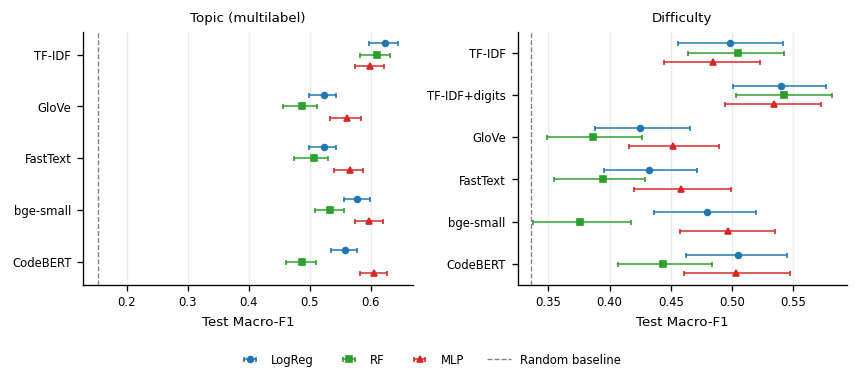

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.1), sharey=False)
specs = [(axes[0], topic, topic_reps, 'ci_low', 'ci_high', topic_base['macro_f1'], 'Topic (multilabel)'),
         (axes[1], diff, diff_reps, 'f1_ci_low', 'f1_ci_high',
          float(diff_base.loc['stratified random', 'macro_f1']) if diff_base is not None else None, 'Difficulty')]
colors = {'logreg': '#1f77b4', 'rf': '#2ca02c', 'mlp': '#d62728'}
markers = {'logreg': 'o', 'rf': 's', 'mlp': '^'}
for ax, df, reps, lo, hi, base, title in specs:
    for i, rep in enumerate(reps):
        for j, m in enumerate(MODELS):
            r = df[(df['rep'] == rep) & (df['model'] == m)].iloc[0]
            y = i + (j - 1) * 0.22
            ax.errorbar(r['test_macro_f1'], y, xerr=[[r['test_macro_f1'] - r[lo]], [r[hi] - r['test_macro_f1']]] if not np.isnan(r[lo]) else None,
                        fmt=markers[m], color=colors[m], ms=3.5, lw=0.9, capsize=1.5, label=MODEL_LABEL[m] if i == 0 else None)
    if base is not None:
        ax.axvline(base, color='gray', ls='--', lw=0.8, label='Random baseline')
    ax.set_yticks(range(len(reps))); ax.set_yticklabels([REP_LABEL[r] for r in reps]); ax.invert_yaxis()
    ax.set_xlabel('Test Macro-F1'); ax.set_title(title)
    ax.grid(axis='x', alpha=0.25)
h, l = axes[0].get_legend_handles_labels()
order = [i for i, y in enumerate(l) if y != 'Random baseline'] + [i for i, y in enumerate(l) if y == 'Random baseline']
fig.legend([h[i] for i in order], [l[i] for i in order],
           loc='lower center', ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=(0, 0.07, 1, 1))
savefig(fig, 'fig_macro_f1_ci')

## 13. Gambar 2: F1 per Label (model topic terbaik menurut CV)

Label diurutkan menurut F1. Angka di sisi kanan = jumlah positif di test set (support); label dengan support kecil punya F1 yang tidak stabil.

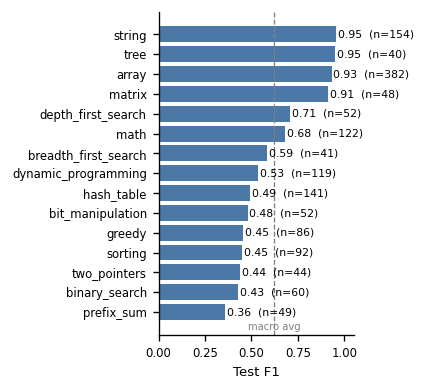

Terendah: ['prefix_sum', 'binary_search', 'two_pointers'] | Tertinggi: ['array', 'tree', 'string']


In [13]:
best_key = f"{topic_best['rep']}|{topic_best['model']}"
pl_path = find_optional('topic_per_label_f1_all.csv')
if pl_path is None:
    print('topic_per_label_f1_all.csv tidak ditemukan: Gambar 2 dilewati.')
else:
    pl = pd.read_csv(pl_path, index_col=0)
    assert best_key in pl.columns, f'{best_key} tidak ada di {list(pl.columns)}'
    s = pl[[ 'support_test', best_key]].rename(columns={best_key: 'f1'}).sort_values('f1')
    save_table(s.reset_index().rename(columns={'index': 'topic'}), 'table_topic_per_label_best')
    to_md(s.sort_values('f1', ascending=False).reset_index().rename(columns={'index': 'topic'}),
          f'F1 per label ({REP_LABEL[topic_best["rep"]]} x {MODEL_LABEL[topic_best["model"]]})')
    fig, ax = plt.subplots(figsize=(3.5, 3.3))
    ax.barh(range(len(s)), s['f1'], color='#4c78a8')
    ax.set_yticks(range(len(s))); ax.set_yticklabels(s.index)
    for i, (f, n) in enumerate(zip(s['f1'], s['support_test'])):
        ax.text(f + 0.01, i, f'{f:.2f}  (n={int(n)})', va='center', fontsize=6.5)
    ax.axvline(topic_best['test_macro_f1'], color='gray', ls='--', lw=0.8)
    ax.text(topic_best['test_macro_f1'], -0.9, 'macro avg', fontsize=6, ha='center', color='gray')
    ax.set_xlim(0, 1.05); ax.set_xlabel('Test F1')
    fig.tight_layout()
    savefig(fig, 'fig_topic_per_label_f1')
    KEY['topic_hardest'] = s.index[:3].tolist(); KEY['topic_easiest'] = s.index[-3:].tolist()
    print('Terendah:', KEY['topic_hardest'], '| Tertinggi:', KEY['topic_easiest'])

## 14. Gambar 3: Confusion Matrix Difficulty

Dua model berdampingan: terbaik menurut CV tanpa TF-IDF+digits (Notebook 05) dan terbaik Notebook 05b (`TF-IDF+digits`). Nilai dinormalisasi per baris (recall per kelas). Catatan: ini perbandingan antar dua model berbeda, jadi indikatif.

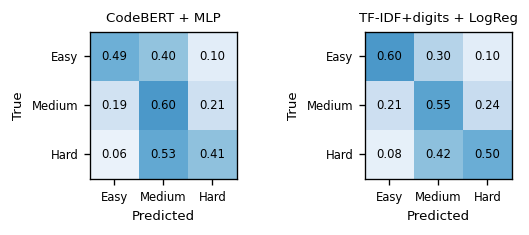

,model,recall_Easy,recall_Medium,recall_Hard
0,CodeBERT + MLP,0.494,0.596,0.41
1,TF-IDF+digits + LogReg,0.596,0.547,0.50


Kesalahan Easy<->Hard (% dari semua soal test): 4.61


In [14]:
def read_cm(name):
    p = find_optional(name)
    if p is None:
        return None
    m = pd.read_csv(p, index_col=0).values.astype(float)
    return m


cm_old = read_cm('difficulty_confusion_best.csv')
cm_new = read_cm('difficulty_tfidf_digits_confusion.csv')
_b_old = diff[diff['rep'] != 'tfidf_digits'].sort_values('cv_macro_f1_mean', ascending=False).iloc[0]
_b_new = diff[diff['rep'] == 'tfidf_digits'].sort_values('cv_macro_f1_mean', ascending=False).iloc[0]
panels = [(cm_old, f"{REP_LABEL[_b_old['rep']]} + {MODEL_LABEL[_b_old['model']]}"),
          (cm_new, f"{REP_LABEL[_b_new['rep']]} + {MODEL_LABEL[_b_new['model']]}")]
panels = [(m, t) for m, t in panels if m is not None]
if not panels:
    print('File confusion matrix tidak ditemukan: Gambar 3 dilewati.')
else:
    fig, axes = plt.subplots(1, len(panels), figsize=(3.5 * len(panels) / 1.6 + 0.4, 2.0), squeeze=False)
    rec_rows = []
    for ax, (m, title) in zip(axes[0], panels):
        mn = m / m.sum(axis=1, keepdims=True)
        ax.imshow(mn, cmap='Blues', vmin=0, vmax=1)
        ax.set_xticks(range(3)); ax.set_xticklabels(CLASS_NAMES); ax.set_yticks(range(3)); ax.set_yticklabels(CLASS_NAMES)
        ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title(title)
        for i in range(3):
            for j in range(3):
                ax.text(j, i, f'{mn[i, j]:.2f}', ha='center', va='center', fontsize=7, color='white' if mn[i, j] > 0.6 else 'black')
        rec_rows.append(dict(zip(['model'] + [f'recall_{c}' for c in CLASS_NAMES], [title] + list(np.round(np.diag(mn), 3)))))
        ax.spines[:].set_visible(True)
    fig.tight_layout()
    savefig(fig, 'fig_difficulty_confusion')
    rec = pd.DataFrame(rec_rows)
    save_table(rec, 'table_difficulty_recall_per_class')
    to_md(rec, 'Recall per kelas difficulty')
    display(rec)
    if cm_new is not None:
        mn = cm_new / cm_new.sum(axis=1, keepdims=True)
        KEY['easy_hard_confusion_pct'] = round(float((cm_new[0, 2] + cm_new[2, 0]) / cm_new.sum() * 100), 2)
        print('Kesalahan Easy<->Hard (% dari semua soal test):', KEY['easy_hard_confusion_pct'])

## 15. Simpan Semua Tabel Markdown dan Angka Kunci

`all_tables.md` berisi semua tabel dalam satu file; salin ke Word lalu format ke gaya tabel IEEE. `key_numbers.json` berisi angka yang sering dikutip.

In [15]:
with open(os.path.join(OUT_DIR, 'all_tables.md'), 'w', encoding='utf-8') as f:
    f.write('\n'.join(MD_BLOCKS))
with open(os.path.join(OUT_DIR, 'key_numbers.json'), 'w', encoding='utf-8') as f:
    json.dump(KEY, f, indent=2, ensure_ascii=False, default=float)

print('Tabel :', sorted(os.listdir(TAB_OUT)))
print('Gambar:', sorted(os.listdir(FIG_OUT)))
print(json.dumps(KEY, indent=2, ensure_ascii=False, default=float)[:3000])

Tabel : ['full_difficulty_all_combinations.csv', 'full_topic_all_combinations.csv', 'hyperparams_difficulty.csv', 'hyperparams_topic.csv', 'rq1_sparse_vs_dense.csv', 'rq2_rq3_deltas.csv', 'rq4_task_disparity.csv', 'table_ablation_digits.csv', 'table_ablation_digits_paired.csv', 'table_difficulty_best_per_rep.csv', 'table_difficulty_distribution.csv', 'table_difficulty_pivot.csv', 'table_difficulty_recall_per_class.csv', 'table_oov.csv', 'table_preprocessing_example.csv', 'table_topic_best_per_rep.csv', 'table_topic_distribution.csv', 'table_topic_per_label_best.csv', 'table_topic_pivot.csv', 'table_truncation.csv']
Gambar: ['fig_difficulty_confusion.pdf', 'fig_difficulty_confusion.png', 'fig_macro_f1_ci.pdf', 'fig_macro_f1_ci.png', 'fig_topic_per_label_f1.pdf', 'fig_topic_per_label_f1.png']
{
  "topic_best": {
    "rep": "tfidf",
    "model": "logreg",
    "cv_macro_f1": 0.5979,
    "test_macro_f1": 0.6234,
    "test_micro_f1": 0.6805,
    "test_hamming": 0.1054,
    "ci": [
      0.59

## Cara memakai output ini di paper

1. **Bab III:** Tabel I (distribusi difficulty dan topik), contoh preprocessing, OOV dan pemotongan, hyperparameter.
2. **Bab IV-A (topic):** `table_topic_pivot`, `table_topic_best_per_rep`, `fig_macro_f1_ci` (panel kiri), `fig_topic_per_label_f1`.
3. **Bab IV-B (difficulty):** `table_difficulty_pivot`, `table_difficulty_best_per_rep`, `fig_macro_f1_ci` (panel kanan), `fig_difficulty_confusion`.
4. **Bab IV-C:** `table_ablation_digits`, lalu RQ1–RQ4 dari `rq1_sparse_vs_dense`, `rq2_rq3_deltas`, `rq4_task_disparity`.
5. **Aturan klaim:** sebut model "terbaik menurut CV"; bila interval 95% dua model saling memuat, tulis "tidak terbedakan secara statistik", bukan "unggul".
6. Halaman terbatas (5–7): pakai satu tabel pivot per tugas ditambah satu tabel metrik lengkap; tabel 18 baris cukup ada di repositori kode.